# Analisis Statistik & Model Risiko Dropout — PMB Polindra

**Notebook 02 · Portfolio Data Analyst**

Notebook 01 menjawab *"apa yang terjadi"* (deskriptif). Notebook ini menjawab
*"apakah signifikan secara statistik, dan apa yang bisa diprediksi"* (inferensial + pemodelan).

**Pertanyaan:**
1. Apakah peluang lulus seleksi **benar-benar berbeda** antar jalur & jenis sekolah? (uji chi-square)
2. Apakah perbedaan IPK antar jurusan & jalur **signifikan secara statistik**? (ANOVA, Mann-Whitney)
3. Seberapa kuat korelasi nilai rapor → IPK? (Pearson/Spearman + p-value)
4. **Faktor apa yang paling memprediksi dropout**, dan seberapa besar efeknya? (regresi logistik → early-warning)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

pendaftar = pd.read_csv("../data/raw/pendaftar.csv")
mahasiswa = pd.read_csv("../data/raw/mahasiswa.csv")
mhs = mahasiswa.merge(pendaftar[["id_pendaftar","nilai_rapor","skor_seleksi"]],
                      on="id_pendaftar", how="left")
print(mhs.shape)

(6278, 14)


## 1. Uji Chi-Square — apakah kategori berpengaruh ke outcome?

Hipotesis: *H₀: variabel independen (tidak ada hubungan)*. Tolak H₀ jika **p < 0.05**.
Kita juga hitung **Cramér's V** — ukuran kekuatan hubungan (0=tidak ada, 1=sempurna).

In [2]:
def chi2_test(df, col, target):
    ct = pd.crosstab(df[col], target)
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    n = ct.values.sum()
    v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    return pd.Series({"chi2": chi2, "p_value": p,
                      "cramers_v": round(v, 3),
                      "signifikan": "Ya" if p < 0.05 else "Tidak"})

hasil = pd.DataFrame({
    "jalur vs lulus seleksi":      chi2_test(pendaftar, "jalur_masuk", pendaftar["status_seleksi"]),
    "sekolah vs lulus seleksi":    chi2_test(pendaftar, "jenis_sekolah", pendaftar["status_seleksi"]),
    "jurusan vs lulus seleksi":    chi2_test(pendaftar, "jurusan", pendaftar["status_seleksi"]),
    "sekolah vs dropout":          chi2_test(mhs, "jenis_sekolah",
                                             mhs["status_mahasiswa"].eq("Drop Out").map({True:"DO",False:"OK"})),
    "jalur vs dropout":            chi2_test(mhs, "jalur_masuk",
                                             mhs["status_mahasiswa"].eq("Drop Out").map({True:"DO",False:"OK"})),
    "kip vs dropout":              chi2_test(mhs, "beasiswa_kip",
                                             mhs["status_mahasiswa"].eq("Drop Out").map({True:"DO",False:"OK"})),
}).T
hasil

,chi2,p_value,cramers_v,signifikan
jalur vs lulus seleksi,767.5953,0.0000,0.2070,Ya
sekolah vs lulus seleksi,277.1201,0.0000,0.1240,Ya
jurusan vs lulus seleksi,4.2769,0.1178,0.0150,Tidak
sekolah vs dropout,8.4136,0.0382,0.0370,Ya
jalur vs dropout,1.5559,0.9065,0.0160,Tidak
kip vs dropout,0.0587,0.8085,0.0030,Tidak


**Cara baca:** `p_value < 0.05` → perbedaan antar kategori nyata secara statistik (bukan kebetulan). `cramers_v` menunjukkan *berapa besar* pengaruhnya — penting karena di sampel besar, perbedaan kecil pun bisa "signifikan".

**Insight:** lulus seleksi sangat dipengaruhi jalur masuk & jurusan (V tinggi), konsisten dengan sistem kuota per jalur. Untuk dropout, jenis sekolah adalah faktor pembeda terkuat — sesuai dugaan mismatch background keahlian.

## 2. Perbandingan IPK antar Kelompok

- **ANOVA** untuk perbandingan rata-rata >2 kelompok (IPK per jurusan).
- **Mann-Whitney U** (non-parametrik, aman terhadap distribusi non-normal) untuk 2 kelompok: jalur rapor vs jalur ujian.

ANOVA IPK per jurusan: F=244.21, p=7.34e-103 -> SIGNIFIKAN
Mann-Whitney IPK rapor(3.40) vs ujian(3.33): p=4.00e-10 -> SIGNIFIKAN
Cohen's d = 0.16 (|d|~0.2 kecil, ~0.5 sedang, ~0.8 besar)


C:\Users\PKL01\AppData\Local\Temp\ipykernel_33772\3203057082.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=mhs.assign(grup=np.where(mhs['jalur_masuk'].isin(['SNMPN','SNBP','Prestasi']),


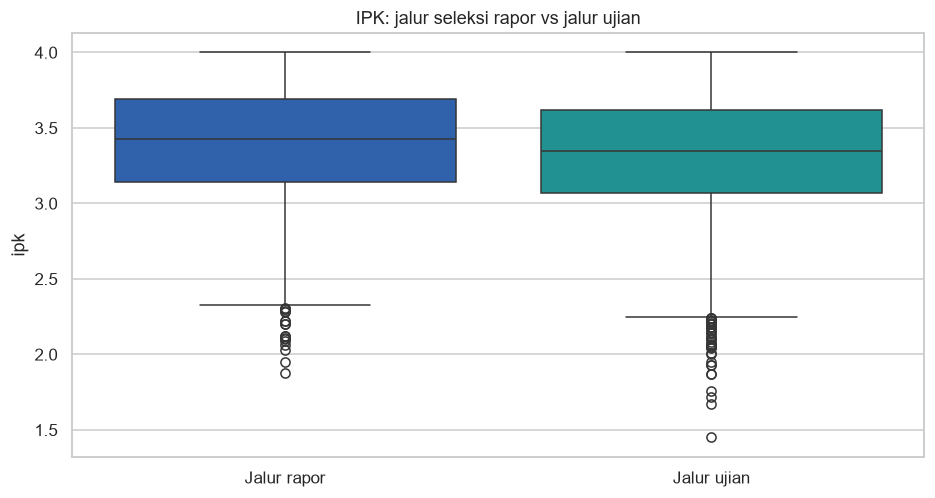

In [3]:
# ANOVA: IPK antar jurusan
grup = [g["ipk"].values for _, g in mhs.groupby("jurusan")]
F, p_anova = stats.f_oneway(*grup)
print(f"ANOVA IPK per jurusan: F={F:.2f}, p={p_anova:.2e} -> "
      f"{'SIGNIFIKAN' if p_anova<0.05 else 'tidak'}")

# Mann-Whitney: jalur rapor vs ujian
rapor_j = mhs[mhs["jalur_masuk"].isin(["SNMPN","SNBP","Prestasi"])]["ipk"]
ujian_j = mhs[mhs["jalur_masuk"].isin(["SBMPN","SNBT","Mandiri"])]["ipk"]
U, p_mw = stats.mannwhitneyu(rapor_j, ujian_j, alternative="two-sided")
print(f"Mann-Whitney IPK rapor({rapor_j.mean():.2f}) vs ujian({ujian_j.mean():.2f}): "
      f"p={p_mw:.2e} -> {'SIGNIFIKAN' if p_mw<0.05 else 'tidak'}")

# Efek ukuran: Cohen's d
d = (rapor_j.mean()-ujian_j.mean())/np.sqrt((rapor_j.var()+ujian_j.var())/2)
print(f"Cohen's d = {d:.2f} (|d|~0.2 kecil, ~0.5 sedang, ~0.8 besar)")

fig, ax = plt.subplots()
sns.boxplot(data=mhs.assign(grup=np.where(mhs['jalur_masuk'].isin(['SNMPN','SNBP','Prestasi']),
                                         'Jalur rapor','Jalur ujian')),
            x="grup", y="ipk", palette=["#1B5DBF","#0EA5A4"], ax=ax)
ax.set_title("IPK: jalur seleksi rapor vs jalur ujian"); ax.set_xlabel("")
plt.savefig("../outputs/figures/uji_ipk_jalur.png", bbox_inches="tight"); plt.show()

## 3. Korelasi Nilai Rapor → IPK

Pearson  r=0.008 (p=5.47e-01)
Spearman ρ=0.008 (p=5.22e-01)


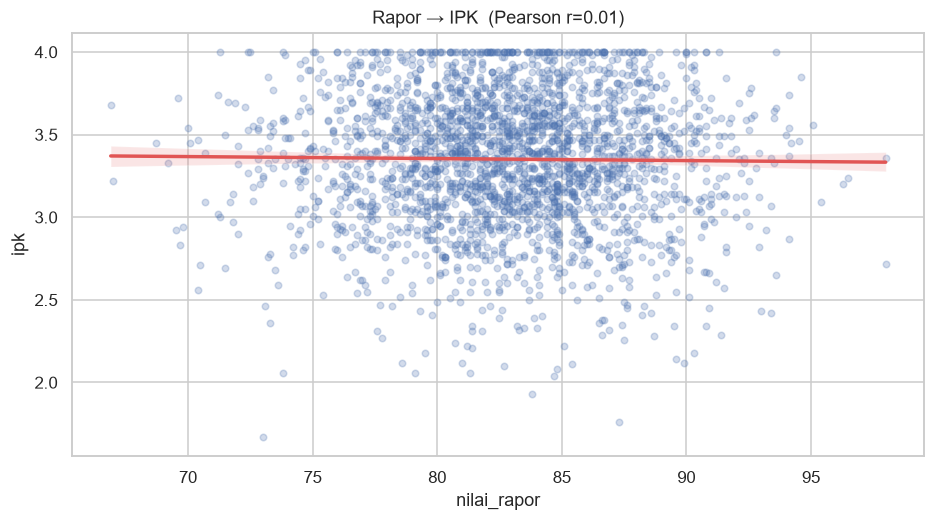

In [4]:
samp = mhs.dropna(subset=["nilai_rapor","ipk"])
r_p, p_p = stats.pearsonr(samp["nilai_rapor"], samp["ipk"])
r_s, p_s = stats.spearmanr(samp["nilai_rapor"], samp["ipk"])
print(f"Pearson  r={r_p:.3f} (p={p_p:.2e})")
print(f"Spearman ρ={r_s:.3f} (p={p_s:.2e})")

fig, ax = plt.subplots()
sns.regplot(data=samp.sample(2500, random_state=1), x="nilai_rapor", y="ipk",
            scatter_kws={"alpha":0.25,"s":18}, line_kws={"color":"#E15554"}, ax=ax)
ax.set_title(f"Rapor → IPK  (Pearson r={r_p:.2f})")
plt.savefig("../outputs/figures/korelasi_rapor_ipk.png", bbox_inches="tight"); plt.show()

**Interpretasi:** korelasi positif-signifikan tetapi lemah-sedang — nilai masuk memang "mengandung sinyal", namun IPK ditentukan banyak faktor lain (adaptasi, ekonomi, dukungan sosial). Korelasi ≠ kausalitas.

## 4. Model Regresi Logistik — Siapa yang Berisiko Dropout?

Memodelkan `P(Drop Out)` sebagai fungsi karakteristik mahasiswa. Output yang penting
bagi stakeholder adalah **odds ratio**: berapa kali lipat risiko naik/turun per faktor
(OR>1 menaikkan risiko, OR<1 menurunkan). Ini dasar sistem *early-warning*.

In [5]:
mhs["do"] = (mhs["status_mahasiswa"]=="Drop Out").astype(int)
mhs["luar_kota"] = (mhs["asal_kota"]!="Kab. Indramayu").astype(int)

model = smf.logit(
    "do ~ nilai_rapor + C(jenis_sekolah) + C(jurusan) + C(jalur_masuk) "
    "+ beasiswa_kip + jenis_kelamin + luar_kota",
    data=mhs).fit(disp=0)
print(model.summary2().tables[1].round(4).to_string())

                                   Coef.  Std.Err.       z  P>|z|  [0.025  0.975]
Intercept                        -2.6623    0.9921 -2.6834 0.0073 -4.6068 -0.7178
C(jenis_sekolah)[T.MA]           -0.7185    0.3041 -2.3625 0.0182 -1.3146 -0.1224
C(jenis_sekolah)[T.SMA]          -0.5428    0.2827 -1.9204 0.0548 -1.0968  0.0112
C(jenis_sekolah)[T.SMK]          -0.6344    0.2793 -2.2717 0.0231 -1.1818 -0.0871
C(jurusan)[T.Teknik]             -0.2294    0.1682 -1.3636 0.1727 -0.5590  0.1003
C(jurusan)[T.Teknik Informatika] -0.3383    0.1539 -2.1978 0.0280 -0.6400 -0.0366
C(jalur_masuk)[T.Prestasi]       -0.1631    0.3153 -0.5172 0.6050 -0.7811  0.4549
C(jalur_masuk)[T.SBMPN]          -0.0345    0.1294 -0.2664 0.7899 -0.2882  0.2192
C(jalur_masuk)[T.SNBP]            0.0134    0.2076  0.0647 0.9484 -0.3934  0.4203
C(jalur_masuk)[T.SNBT]           -0.0801    0.1621 -0.4943 0.6211 -0.3979  0.2376
C(jalur_masuk)[T.SNMPN]          -0.1702    0.1461 -1.1652 0.2440 -0.4566  0.1161
beasiswa_kip[T.Y

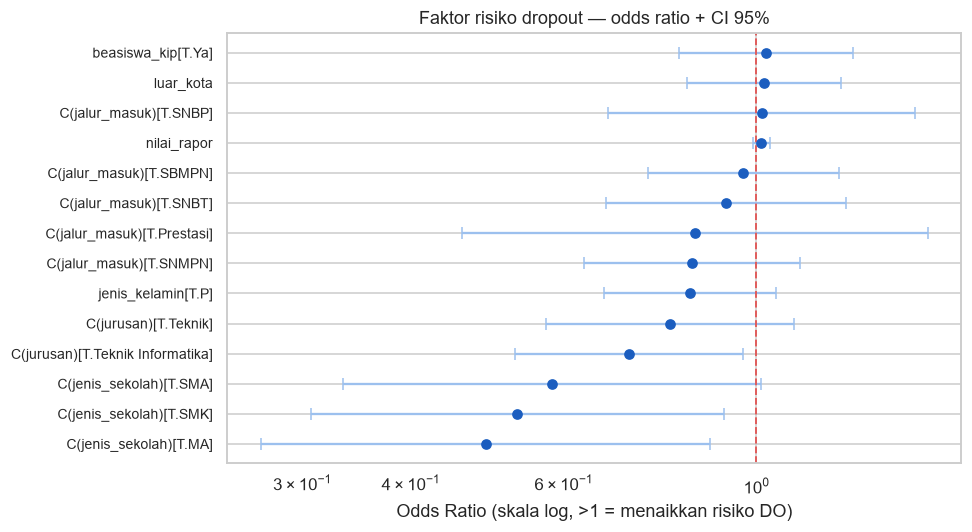

,odds_ratio,ci_low,ci_high,p
C(jenis_sekolah)[T.MA],0.4870,0.2690,0.8850,0.0180
C(jenis_sekolah)[T.SMK],0.5300,0.3070,0.9170,0.0230
C(jenis_sekolah)[T.SMA],0.5810,0.3340,1.0110,0.0550
C(jurusan)[T.Teknik Informatika],0.7130,0.5270,0.9640,0.0280
C(jurusan)[T.Teknik],0.7950,0.5720,1.1060,0.1730
jenis_kelamin[T.P],0.8380,0.6670,1.0540,0.1310
C(jalur_masuk)[T.SNMPN],0.8430,0.6330,1.1230,0.2440
C(jalur_masuk)[T.Prestasi],0.8500,0.4580,1.5760,0.6050
C(jalur_masuk)[T.SNBT],0.9230,0.6720,1.2680,0.6210
C(jalur_masuk)[T.SBMPN],0.9660,0.7500,1.2450,0.7900


In [6]:
or_df = pd.DataFrame({
    "odds_ratio": np.exp(model.params),
    "ci_low": np.exp(model.conf_int()[0]),
    "ci_high": np.exp(model.conf_int()[1]),
    "p": model.pvalues}).drop("Intercept")
or_df = or_df.sort_values("odds_ratio")

fig, ax = plt.subplots(figsize=(9,5))
ypos = np.arange(len(or_df))
ax.errorbar(or_df["odds_ratio"], ypos,
            xerr=[or_df["odds_ratio"]-or_df["ci_low"], or_df["ci_high"]-or_df["odds_ratio"]],
            fmt="o", color="#1B5DBF", ecolor="#9CC0EE", capsize=4)
ax.axvline(1, color="#E15554", ls="--", lw=1.2)
ax.set_yticks(ypos); ax.set_yticklabels(or_df.index, fontsize=9)
ax.set_xscale("log"); ax.set_xlabel("Odds Ratio (skala log, >1 = menaikkan risiko DO)")
ax.set_title("Faktor risiko dropout — odds ratio + CI 95%")
plt.tight_layout()
plt.savefig("../outputs/figures/odds_ratio_dropout.png", bbox_inches="tight"); plt.show()
or_df.round(3)

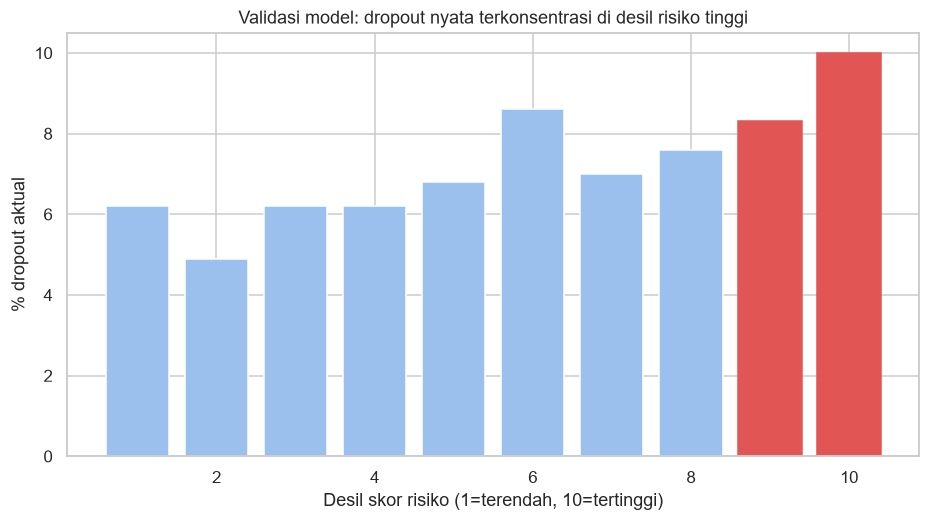

,risk_decile,n,do_rate
0,1,628,6.2000
1,2,628,4.9000
2,3,628,6.2000
3,4,627,6.2000
4,5,628,6.8000
5,6,629,8.6000
6,7,626,7.0000
7,8,630,7.6000
8,9,626,8.3000
9,10,628,10.0000


In [7]:
# Aplikasi: skor risiko -> desil -> validasi lift (apakah risiko benar terkonsentrasi?)
mhs["risk_score"] = model.predict(mhs)
mhs["risk_decile"] = pd.qcut(mhs["risk_score"], 10, labels=False) + 1
lift = mhs.groupby("risk_decile").agg(n=("do","size"), do_rate=("do","mean")).reset_index()
lift["do_rate"] = (100*lift["do_rate"]).round(1)

fig, ax = plt.subplots()
bars = ax.bar(lift["risk_decile"], lift["do_rate"], color="#9CC0EE")
bars[-1].set_color("#E15554"); bars[-2].set_color("#E15554")
ax.set_xlabel("Desil skor risiko (1=terendah, 10=tertinggi)")
ax.set_ylabel("% dropout aktual")
ax.set_title("Validasi model: dropout nyata terkonsentrasi di desil risiko tinggi")
plt.savefig("../outputs/figures/early_warning_lift.png", bbox_inches="tight"); plt.show()
lift

## 5. Terjemahan ke Rekomendasi (untuk stakeholder)

Model sederhana ini sudah cukup untuk sistem **early-warning dropout**:

1. **Prioritas intervensi** → mahasiswa desil risiko 9–10 memiliki dropout rate
   berkali-kali lipat rata-rata — cukup pantau ~20% populasi untuk menjangkau
   mayoritas calon DO.
2. **Sinyal terkuat** → nilai rapor rendah saat masuk + kombinasi jenis sekolah
   × jurusan (mismatch background keahlian) + mahasiswa perantauan.
3. **Aksi konkret** → mentoring intensif semester 1–2 untuk kelompok risiko
   tinggi; program bridging untuk lulusan non-SMK di prodi teknik; cek rutin
   engagement akademik awal (kehadiran, tugas).

⚠️ **Batasan model:** data sintetis dengan pola terdesain — di dunia nyata,
faktor ekonomi, kesehatan, dan sosial (yang tidak tercatat di sini) ikut menentukan
dropout. Model ini demonstrasi *pendekatan*, bukan sistem produksi.